# Multi-Armed Bandits (Thompson Sampling)

An A/B test splits the traffic evenly until the end, then chooses the winner. During the test, half of the users
(or two thirds, with three arms) see a worse variant. A **multi-armed bandit** changes the split while the test runs:
it sends more users to the variants that look better. This lesson builds three bandit policies, measures their
cost with **regret**, and evaluates them offline on the real Hillstrom logs.

**After this lesson you can:**

1. Define the explore/exploit trade-off and the cumulative regret of a policy.
2. Implement epsilon-greedy, UCB1 and Thompson sampling (Beta-Bernoulli) with NumPy, vectorised over many runs.
3. Evaluate a bandit policy offline on randomized logs with the replay method (Li et al., 2011).
4. Show why the naive means of a bandit experiment have a bias, and choose between a bandit and an A/B test.
5. Extend Thompson sampling to a simple contextual bandit with one context feature.

**Data:** Hillstrom MineThatData E-Mail Analytics challenge (2008): 64,000 customers in a randomized e-mail test.
The three arms are the three e-mail groups, and the reward is `visit` (the customer visited the website).
**Services:** none.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: pinned datasets

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})

df = pd.read_csv(datasets.fetch("hillstrom_email.csv"))
ARMS = ["Mens E-Mail", "Womens E-Mail", "No E-Mail"]
K = len(ARMS)
MU = df.groupby("segment")["visit"].mean().reindex(ARMS).to_numpy()   # true Bernoulli means of the simulation
BEST = MU.max()
print(pd.DataFrame({"users": df["segment"].value_counts().reindex(ARMS), "visit rate": MU.round(4)}, index=ARMS))
print(f"best arm: {ARMS[MU.argmax()]} ({BEST:.4f}) | gap to 2nd: {BEST - np.sort(MU)[-2]:.4f} | "
      f"gap to 3rd: {BEST - MU.min():.4f}")

               users  visit rate
Mens E-Mail    21307      0.1828
Womens E-Mail  21387      0.1514
No E-Mail      21306      0.1062
best arm: Mens E-Mail (0.1828) | gap to 2nd: 0.0314 | gap to 3rd: 0.0766


## 1. Explore, Exploit and Regret

A **policy** chooses one **arm** (variant) for each user and then observes a **reward** (here 1 if the user visits,
else 0). The policy does not know the true mean rewards $\mu_1, \dots, \mu_K$. It must **explore** (try arms to learn
their means) and **exploit** (send users to the arm that looks best). Too little exploration can lock the policy on
a wrong arm. Too much exploration wastes users on bad arms.

The **regret** after $T$ users measures the cost of learning. It compares the policy with an oracle that always plays
the best arm $\mu^* = \max_a \mu_a$:

$$
R_T = T\,\mu^* - \mathbb{E}\Big[\sum_{t=1}^{T} \mu_{A_t}\Big] = \sum_{a} \Delta_a\, \mathbb{E}[N_a(T)],
\qquad \Delta_a = \mu^* - \mu_a .
$$

$A_t$ is the arm at step $t$ and $N_a(T)$ is the number of times the policy plays arm $a$. An A/B test with a
uniform split has a regret that grows linearly in $T$. Good bandit policies have a regret that grows like $\log T$.

The cell computes the gaps and the regret per user of the uniform split, $\frac{1}{K}\sum_a \Delta_a$.

In [2]:
gaps = BEST - MU
print("gaps Delta_a:", " | ".join(f"{a} {g:.4f}" for a, g in zip(ARMS, gaps)))
print(f"uniform split: regret per user = {gaps.mean():.4f} -> {gaps.mean() * 21_333:,.0f} lost visits per 21,333 users")

gaps Delta_a: Mens E-Mail 0.0000 | Womens E-Mail 0.0314 | No E-Mail 0.0766
uniform split: regret per user = 0.0360 -> 768 lost visits per 21,333 users


## 2. Three Policies

All three policies keep, for each arm, the number of plays $N_a$ and the sum of rewards $S_a$.

1. **Epsilon-greedy**: with probability $\varepsilon$ play a random arm, else play the arm with the highest
   mean $\hat\mu_a = S_a / N_a$. This lesson uses $\varepsilon = 0.1$.
2. **UCB1** (Auer et al., 2002): play each arm once, then play the arm with the highest upper confidence bound
   $\hat\mu_a + \sqrt{2 \ln t / N_a}$. Arms with few plays get a large bonus.
3. **Thompson sampling** (Thompson, 1933): keep a Beta posterior for each arm. Draw one sample from each posterior
   and play the arm with the largest sample. With the prior $\text{Beta}(1, 1)$ (uniform) and a reward $r \in \{0, 1\}$,
   the update is

$$
\mu_a \mid \text{data} \sim \text{Beta}(1 + S_a,\ 1 + N_a - S_a), \qquad
(\alpha_a, \beta_a) \leftarrow (\alpha_a + r,\ \beta_a + 1 - r).
$$

Thompson sampling plays each arm with the posterior probability that this arm is the best one. So it explores
an arm as long as the data cannot exclude that the arm is the best.

The simulation below is synthetic: it draws Bernoulli rewards with the real Hillstrom visit rates. It runs 200
independent bandits in parallel (one row per run) for 21,333 users, the size of one Hillstrom group.

In [3]:
EPS = 0.1
POLICIES = ["uniform (A/B test)", "epsilon-greedy", "UCB1", "Thompson"]

def choose(policy, counts, sums, rng):
    # Return one arm per run. counts, sums: arrays of shape (runs, K).
    runs = counts.shape[0]
    if policy == "uniform (A/B test)":
        return rng.integers(0, K, runs)
    if policy == "Thompson":
        return rng.beta(1 + sums, 1 + counts - sums).argmax(1)
    means = sums / np.maximum(counts, 1)
    if policy == "epsilon-greedy":
        arm = np.where(rng.random(runs) < EPS, rng.integers(0, K, runs), means.argmax(1))
    else:                                          # UCB1
        t = counts.sum(1, keepdims=True)
        arm = (means + np.sqrt(2 * np.log(np.maximum(t, 1)) / np.maximum(counts, 1))).argmax(1)
    untried = counts == 0                          # play every arm once first
    return np.where(untried.any(1), untried.argmax(1), arm)

def simulate(policy, horizon, runs, seed):
    # Run `runs` bandits for `horizon` users. Return per-step mean regret, per-step allocation, final counts/sums.
    rng = np.random.default_rng(seed)
    counts, sums = np.zeros((runs, K)), np.zeros((runs, K))
    regret, alloc = np.zeros(horizon), np.zeros((horizon, K))
    reward_total = np.zeros(runs)
    rows = np.arange(runs)
    for t in range(horizon):
        arm = choose(policy, counts, sums, rng)
        reward = rng.random(runs) < MU[arm]
        counts[rows, arm] += 1
        sums[rows, arm] += reward
        reward_total += reward
        regret[t] = gaps[arm].mean()
        alloc[t] = np.bincount(arm, minlength=K) / runs
    return dict(regret=regret, alloc=alloc, counts=counts, sums=sums, avg_reward=reward_total / horizon)

T_SIM, RUNS = 21_333, 200
sim = {p: simulate(p, T_SIM, RUNS, seed=i) for i, p in enumerate(POLICIES)}
rows = []
for p, r in sim.items():
    share = r["counts"].sum(0) / r["counts"].sum()
    rows.append({"policy": p, "regret R_T": r["regret"].sum(), "lost visits per 1,000 users": 1000 * r["regret"].mean(),
                 "avg reward": r["avg_reward"].mean(), **{f"share {a.split()[0]}": s for a, s in zip(ARMS, share)}})
sim_table = pd.DataFrame(rows).set_index("policy")
print(sim_table.round(3).to_string())

                    regret R_T  lost visits per 1,000 users  avg reward  share Mens  share Womens  share No
policy                                                                                                     
uniform (A/B test)     767.176                       35.962       0.147       0.334         0.333     0.333
epsilon-greedy         101.593                        4.762       0.178       0.899         0.066     0.035
UCB1                   256.537                       12.025       0.171       0.723         0.204     0.074
Thompson                45.179                        2.118       0.181       0.947         0.042     0.010


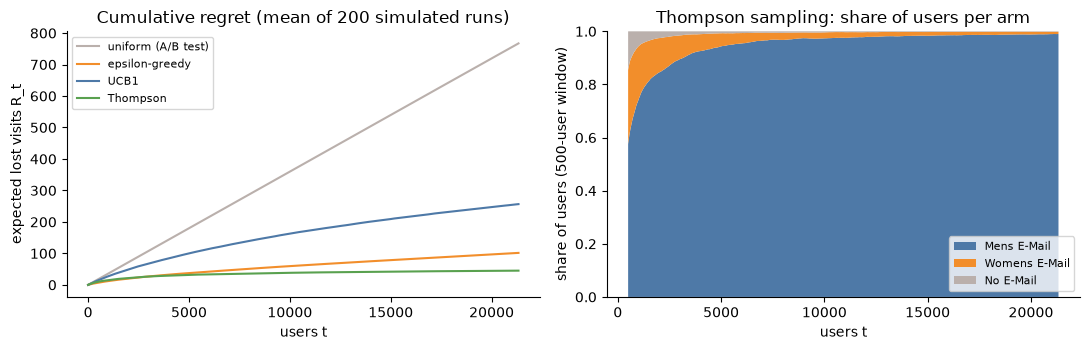

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
colors = dict(zip(POLICIES, ["#BAB0AC", "#F28E2B", "#4E79A7", "#59A14F"]))
steps = np.arange(1, T_SIM + 1)
for p, r in sim.items():
    ax[0].plot(steps, np.cumsum(r["regret"]), color=colors[p], label=p)
ax[0].set(title="Cumulative regret (mean of 200 simulated runs)", xlabel="users t", ylabel="expected lost visits R_t")
ax[0].legend(fontsize=8)
w = 500                                            # moving window for the allocation shares
alloc = sim["Thompson"]["alloc"]
smooth = np.array([np.convolve(alloc[:, a], np.ones(w) / w, mode="valid") for a in range(K)])
ax[1].stackplot(np.arange(w, T_SIM + 1), smooth, labels=ARMS, colors=["#4E79A7", "#F28E2B", "#BAB0AC"])
ax[1].set(title="Thompson sampling: share of users per arm", xlabel="users t", ylabel="share of users (500-user window)",
          ylim=(0, 1))
ax[1].legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

The uniform split loses 0.0360 visits per user, so 768 expected visits per 21,333 users. The simulated A/B test
confirms this with a regret of 767.2. The bandits lose much less:

- **Thompson sampling** has the lowest regret: 45.2 lost visits, or 2.1 per 1,000 users. It sends 94.7 % of the
  users to Mens E-Mail. The right plot shows that the share of the best arm passes 90 % within the first 5,000 users.
- **Epsilon-greedy** has a regret of 101.6. It explores 10 % of the time forever, so its regret keeps a linear
  part of $\varepsilon \cdot 0.0360 = 0.0036$ visits per user.
- **UCB1** has a regret of 256.5. Its bonus $\sqrt{2\ln t/N_a}$ assumes rewards anywhere in $[0, 1]$. Visit
  rates are near 0.15 and the gaps are near 0.03, so the bonus is too large. UCB1 explores too much and sends
  only 72.3 % of the users to the best arm.

*Insight: The regret of an A/B test grows linearly with the number of users. Thompson sampling learns the best arm
in a few thousand users and then loses almost nothing, without a tuning parameter.*

## 3. Offline Evaluation with the Replay Method

A simulation needs the true means, but in practice they are unknown. The **replay method** (Li, Chu, Langford &
Wang, 2011) evaluates a policy on logged data instead:

1. Go through the logged events in a random order.
2. Ask the policy which arm it wants for this event.
3. If the arm is the logged arm, accept the event: the policy sees the logged reward and updates.
4. Else, skip the event. The policy does not learn anything from it.

The estimate is the mean reward of the accepted events. This estimate has no bias only if the logging policy chose
the arms uniformly at random, independent of the user. The Hillstrom experiment did exactly this. So the replay
accepts each event with probability $1/3$, and about 21,333 of the 64,000 events count. The cell replays each policy on 50 random
orders of the data.

In [5]:
LOG_ARM = df["segment"].map({a: i for i, a in enumerate(ARMS)}).to_numpy()
LOG_REWARD = df["visit"].to_numpy().astype(float)
LOG_CTX = (df["mens"] + 2 * df["womens"] - 1).to_numpy()   # 0 = mens only, 1 = womens only, 2 = both
CONTEXTS = ["mens only", "womens only", "both"]
REPLAYS = 50

def replay(policy, seed, contextual=False):
    # Replay one policy on REPLAYS random orders of the log. Return the mean accepted reward and accepted count per order.
    rng = np.random.default_rng(seed)
    order = np.argsort(rng.random((REPLAYS, len(df))), axis=1)        # one permutation per replay run
    shape = (REPLAYS, len(CONTEXTS), K) if contextual else (REPLAYS, K)
    counts, sums = np.zeros(shape), np.zeros(shape)
    total, accepted = np.zeros(REPLAYS), np.zeros(REPLAYS)
    rows = np.arange(REPLAYS)
    for i in range(len(df)):
        ev = order[:, i]
        if contextual:                             # one Thompson sampler per context value
            ctx = LOG_CTX[ev]
            arm = choose(policy, counts[rows, ctx], sums[rows, ctx], rng)
        else:
            arm = choose(policy, counts, sums, rng)
        hit = arm == LOG_ARM[ev]
        r = LOG_REWARD[ev] * hit
        idx = (rows[hit], ctx[hit], arm[hit]) if contextual else (rows[hit], arm[hit])
        counts[idx] += 1
        sums[idx] += r[hit]
        total += r
        accepted += hit
    return total / accepted, accepted

rep = {p: replay(p, seed=10 + i) for i, p in enumerate(POLICIES)}
rows = []
for p, (value, acc) in rep.items():
    rows.append({"policy": p, "replay estimate": value.mean(), "replay sd": value.std(ddof=1),
                 "simulation": sim[p]["avg_reward"].mean(), "accepted events": acc.mean()})
replay_table = pd.DataFrame(rows).set_index("policy")
print(replay_table.round(4).to_string())
print(f"best single arm (Mens E-Mail): {BEST:.4f} | uniform split: {MU.mean():.4f}")

                    replay estimate  replay sd  simulation  accepted events
policy                                                                     
uniform (A/B test)           0.1473     0.0021      0.1465         21361.18
epsilon-greedy               0.1778     0.0037      0.1782         21310.98
UCB1                         0.1708     0.0016      0.1706         21334.04
Thompson                     0.1807     0.0008      0.1806         21319.88
best single arm (Mens E-Mail): 0.1828 | uniform split: 0.1468


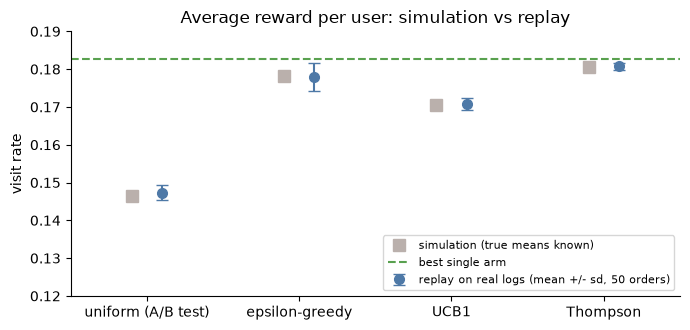

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.4))
x = np.arange(len(POLICIES))
ax.plot(x - 0.1, replay_table["simulation"], "s", ms=8, color="#BAB0AC", label="simulation (true means known)")
ax.errorbar(x + 0.1, replay_table["replay estimate"], yerr=replay_table["replay sd"], fmt="o", ms=7, capsize=4,
            color="#4E79A7", label="replay on real logs (mean +/- sd, 50 orders)")
ax.axhline(BEST, ls="--", color="#59A14F", label="best single arm")
ax.set_xticks(x, POLICIES)
ax.set_xlim(-0.5, len(POLICIES) - 0.5)
ax.set(title="Average reward per user: simulation vs replay", ylabel="visit rate", ylim=(0.12, 0.19))
ax.legend(fontsize=8, loc="lower right"); plt.tight_layout(); plt.show()

The replay accepts between 21,310.98 and 21,361.18 of the 64,000 events on average, depending on the policy.
This matches the acceptance probability of 1/3. The replay estimates agree with the simulation to within 0.0008:

| policy | simulation | replay on the real logs |
| :--- | :--- | :--- |
| uniform | 0.1465 | 0.1473 |
| epsilon-greedy | 0.1782 | 0.1778 |
| UCB1 | 0.1706 | 0.1708 |
| Thompson | 0.1806 | 0.1807 |

This agreement is the main result. The replay did not use the true means; it used only the logged arms and rewards.
So you can rank new policies on old randomized data before you show them to a single user. Thompson sampling gets
0.1807 visits per user, close to the 0.1828 of the best single arm, which no policy can know in advance.

## 4. The Price of Adaptivity: Biased Means

A bandit plays an arm less when the arm looks bad. If an arm looks bad because of bad luck in the first users, the
bandit stops playing it, so the bad luck is never corrected. If an arm looks good because of good luck, the bandit
plays it more, and the extra data corrects the estimate. So the naive sample mean $\hat\mu_a = S_a/N_a$ of an
adaptive experiment has a **negative bias** (Nie et al., 2018). Its naive 95 % confidence interval
$\hat\mu_a \pm 1.96\sqrt{\hat\mu_a(1-\hat\mu_a)/N_a}$ can also miss the true mean more often than 5 %.

The synthetic simulation runs 3,000 short experiments with 1,000 users each and compares Thompson sampling with
the uniform split.

In [7]:
rows = []
for p in ["uniform (A/B test)", "Thompson"]:
    r = simulate(p, horizon=1_000, runs=3_000, seed=99)
    n_a, s_a = r["counts"], r["sums"]
    mean = np.where(n_a > 0, s_a / np.maximum(n_a, 1), np.nan)
    half = 1.96 * np.sqrt(mean * (1 - mean) / np.maximum(n_a, 1))
    covered = np.abs(mean - MU) <= half
    for a, arm in enumerate(ARMS):
        rows.append({"policy": p, "arm": arm, "true mean": MU[a], "avg plays": n_a[:, a].mean(),
                     "bias (pp)": 100 * np.nanmean(mean[:, a] - MU[a]),
                     "CI coverage %": 100 * covered[n_a[:, a] >= 2, a].mean()})
bias_table = pd.DataFrame(rows).set_index(["policy", "arm"])
print(bias_table.round(3).to_string())

                                  true mean  avg plays  bias (pp)  CI coverage %
policy             arm                                                          
uniform (A/B test) Mens E-Mail        0.183    333.487     -0.012         94.967
                   Womens E-Mail      0.151    333.297     -0.010         95.133
                   No E-Mail          0.106    333.216      0.003         94.467
Thompson           Mens E-Mail        0.183    641.611     -0.545         91.467
                   Womens E-Mail      0.151    264.330     -1.562         89.133
                   No E-Mail          0.106     94.059     -1.933         84.200


With the uniform split, the naive means have no bias: the bias is between -0.012 and 0.003 percentage points.
The 95 % intervals cover the true mean in 94.5 % to 95.1 % of the runs.

With Thompson sampling, every arm has a negative bias. The No E-Mail arm gets only 94.1 plays on average. Its bias is -1.933 percentage points, which is 18 %
of its true rate of 0.106. Its interval covers the true mean in only 84.2 % of the runs. Even the best arm has a bias of
-0.545 points.

So a bandit is not a measurement tool. For an unbiased effect estimate with a valid confidence interval, use a
randomized test with fixed allocation (Lesson 03). Another option is to correct the bandit data with inverse
propensity weights. The allocation probabilities of the bandit are the propensities.

## 5. A Contextual Bandit

A **contextual bandit** sees a feature of the user before it chooses an arm. The best arm can then differ between
user groups. The simplest version keeps one Thompson sampler for each value of a categorical context. Here the
context is the purchase history of the last year: men's products only, women's products only, or both.
First, the cell shows the real visit rates per context and arm. Then it replays the contextual Thompson policy.

In [8]:
ctx_rates = (df.assign(context=np.array(CONTEXTS)[LOG_CTX])
             .pivot_table(index="context", columns="segment", values="visit", aggfunc="mean")
             .reindex(index=CONTEXTS, columns=ARMS))
ctx_share = pd.Series(LOG_CTX).value_counts(normalize=True).sort_index().to_numpy()
print(ctx_rates.round(4).to_string())
oracle = (ctx_rates.max(axis=1).to_numpy() * ctx_share).sum()
print(f"oracle with context: {oracle:.4f} | best single arm: {BEST:.4f} | possible gain: {oracle - BEST:.4f}")

value_ctx, acc_ctx = replay("Thompson", seed=20, contextual=True)
value_ts = rep["Thompson"][0]
print(f"replay, Thompson without context: {value_ts.mean():.4f} (sd {value_ts.std(ddof=1):.4f})")
print(f"replay, Thompson with context:    {value_ctx.mean():.4f} (sd {value_ctx.std(ddof=1):.4f})")

segment      Mens E-Mail  Womens E-Mail  No E-Mail
context                                           
mens only         0.1690         0.1109     0.0998
womens only       0.1664         0.1698     0.0958
both              0.3150         0.2517     0.1805
oracle with context: 0.1841 | best single arm: 0.1828 | possible gain: 0.0013


replay, Thompson without context: 0.1807 (sd 0.0008)
replay, Thompson with context:    0.1802 (sd 0.0016)


The table shows that the context changes the best arm only in one group. For customers with women's purchases only,
Womens E-Mail (0.1698) beats Mens E-Mail (0.1664), but by only 0.0034. In the two other groups, Mens E-Mail is
the best arm. So the best possible contextual policy gets 0.1841 visits per user, only 0.0013 more than the best
single arm.

The replay confirms this: the contextual Thompson policy gets 0.1802, the policy without context 0.1807. The
difference is smaller than the replay noise. The contextual policy must learn three samplers, each with a third of
the data, and the possible gain is too small to pay for this. A context helps only when the best arm differs
between large groups of users.

## 6. Bandit or A/B Test?

| question | A/B test (fixed split) | bandit (Thompson sampling) |
| :--- | :--- | :--- |
| goal | measure the effect, decide, learn | earn the most reward during the test |
| regret in the simulation | 767.2 lost visits per 21,333 users | 45.2 lost visits |
| effect estimate | unbiased, valid confidence interval | biased naive means (section 4) |
| guardrail metrics, segments | each arm has enough users for all metrics | weak arms get few users, little data on them |
| best use | product decisions with a long future; effects that you must report | short campaigns, headlines, promotions; many arms; arms that change often |

Use a bandit when the test itself is the product. A one-week promotion or a news headline has no long future after
the test, so the reward during the test is all that matters. Use an A/B test when you will keep the winner for a
long time. Then a correct decision and an unbiased effect size are worth more than the visits that the test
loses. Many teams combine both: an A/B test for the decision, a bandit for the short-lived content.

## Real-World Use Case

The replay method comes from Yahoo! research. Li, Chu, Langford and Wang (WSDM 2011) evaluated news article
recommendation on the Yahoo! front page. For a small random bucket of users, Yahoo! chose
the article uniformly at random. The logs of this bucket were the input of the replay.

The paper showed that the replay estimates agree with
online bucket tests. Yahoo! later published this dataset (Yahoo! Front Page Today Module) for bandit research.

Google Analytics Content Experiments used a Bayesian bandit for web page tests. Steven L. Scott at Google described
the method, which is Thompson sampling, in "A modern Bayesian look at the multi-armed bandit" (2010). The tool sent
more traffic to better variants during the experiment, the trade-off of section 6.